# Tugas UTS: Linear Regression & Logistic Regression

**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman tentang Simple Regression dan Simple Classification pada dataset baru.

**Identitas Mahasiswa**
- Nama: Kawindra Tegar Sastra Carlolintar
- NIM: 241011400554
- Kelas: Reg B
- Random state: 54


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [16]:
# Import library yang diizinkan untuk pengerjaan utama
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 54
NAMA = "Kawindra Tegar Sastra Carlolintar"
NIM = "241011400554"
KELAS = "Reg B"

print(f"Nama: {NAMA}")
print(f"NIM: {NIM}")
print(f"Kelas: {KELAS}")
print(f"Random state: {RANDOM_STATE}")

Nama: Kawindra Tegar Sastra Carlolintar
NIM: 241011400554
Kelas: Reg B
Random state: 54


In [17]:
# Implementasi train_test_split dari materi (tanpa scikit-learn)
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)
    if not 0 < test_size < 1:
        raise ValueError("test_size harus berada di antara 0 dan 1.")
    if len(X) != len(y):
        raise ValueError("Jumlah baris X dan y harus sama.")
    n_test = int(round(len(X) * test_size))
    rng = np.random.RandomState(random_state) if random_state is not None else np.random
    indices = rng.permutation(len(X))
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# Implementasi Linear Regression dengan Normal Equation
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# Implementasi Linear Regression dengan Gradient Descent dari materi
class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate, self.n_iterations = learning_rate, n_iterations
        self.intercept_, self.coefficients_ = 0.0, None
        self.loss_history_, self.beta_history_ = [], []
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1], dtype=float)
        self.loss_history_, self.beta_history_ = [], []
        # errstate menjaga eksperimen learning rate besar tetap dapat diamati
        with np.errstate(over="ignore", invalid="ignore"):
            for _ in range(self.n_iterations):
                y_hat = X_b @ beta
                gradient = X_b.T @ (y_hat - y) / len(y)
                beta = beta - self.learning_rate * gradient
                loss = np.mean((y - X_b @ beta) ** 2)
                self.loss_history_.append(float(loss))
                self.beta_history_.append(beta.copy())
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        return self.intercept_ + X @ self.coefficients_

# Implementasi Logistic Regression dengan Gradient Descent dari materi
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate, self.n_iterations = learning_rate, n_iterations
        self.intercept_, self.coefficients_ = 0.0, None
        self.loss_history_, self.beta_history_ = [], []
    def _sigmoid(self, z):
        z = np.asarray(z, dtype=float)
        # Bentuk stabil untuk menghindari overflow pada exp untuk nilai ekstrem
        out = np.empty_like(z)
        positive = z >= 0
        out[positive] = 1 / (1 + np.exp(-z[positive]))
        ez = np.exp(z[~positive])
        out[~positive] = ez / (1 + ez)
        return out
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1], dtype=float)
        self.loss_history_, self.beta_history_ = [], []
        for _ in range(self.n_iterations):
            p = self._sigmoid(X_b @ beta)
            gradient = X_b.T @ (p - y) / len(y)
            beta = beta - self.learning_rate * gradient
            p_loss = np.clip(self._sigmoid(X_b @ beta), 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(p_loss) + (1 - y) * np.log(1 - p_loss))
            self.loss_history_.append(float(loss))
            self.beta_history_.append(beta.copy())
        self.intercept_, self.coefficients_ = beta[0], beta[1:]
        return self
    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(1, -1) if len(self.coefficients_) > 1 else X.reshape(-1, 1)
        return self._sigmoid(self.intercept_ + X @ self.coefficients_)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    denom = cm[0, 1] + cm[1, 1]
    return cm[1, 1] / denom if denom else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    denom = cm[1, 1] + cm[1, 0]
    return cm[1, 1] / denom if denom else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) else 0.0

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


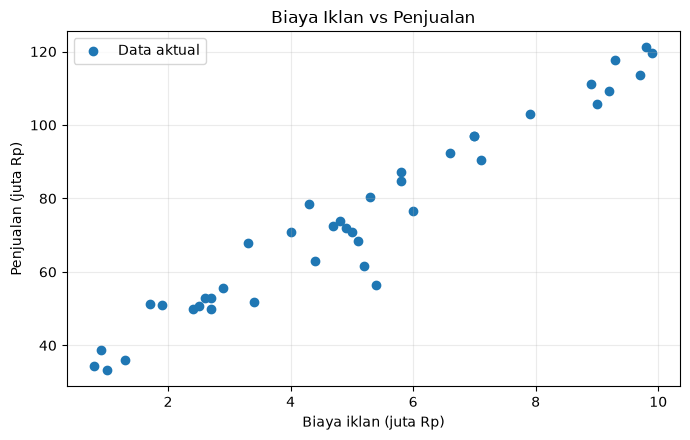

In [18]:
# A1: membaca data, memisahkan fitur/target, dan visualisasi
ads_data = pd.read_csv("Ads_Data.csv")
display(ads_data.head())
print("Jumlah baris data:", len(ads_data))
X = ads_data[["BiayaIklan"]].to_numpy(dtype=float)
y = ads_data["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 4.5))
plt.scatter(X[:, 0], y, label="Data aktual")
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [19]:
# A2: pembagian data 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [20]:
# A3: melatih model dengan Normal Equation
regressor = LinearRegression().fit(X_train, y_train)
print(f"Intercept (b): {regressor.intercept_:.4f}")
print(f"Koefisien (m): {regressor.coefficients_[0]:.4f}")
print(f"Persamaan: ŷ = {regressor.intercept_:.4f} + ({regressor.coefficients_[0]:.4f} × BiayaIklan)")

Intercept (b): 27.8884
Koefisien (m): 9.3474
Persamaan: ŷ = 27.8884 + (9.3474 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Model menghasilkan persamaan ŷ = 27,8884 + 9,3474 × BiayaIklan. Koefisien 9,3474 berarti setiap kenaikan biaya iklan sebesar Rp1 juta berkaitan dengan kenaikan prediksi penjualan sekitar Rp9,35 juta menurut model. Hubungan ini merupakan pola pada dataset, bukan bukti bahwa biaya iklan menjadi satu-satunya penyebab perubahan penjualan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [21]:
# A4: fungsi metrik regresi buatan sendiri menggunakan NumPy
def mean_absolute_error(y_true, y_pred):
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))))
def mean_squared_error(y_true, y_pred):
    return float(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))
def root_mean_squared_error(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))
def r2_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1 - ss_res / ss_tot) if ss_tot != 0 else float("nan")

evaluasi_regresi = []
for nama_data, X_eval, y_eval in [
    ("Training", X_train, y_train), ("Testing", X_test, y_test)
]:
    pred_eval = regressor.predict(X_eval)
    evaluasi_regresi.append({
        "Data": nama_data,
        "MAE": mean_absolute_error(y_eval, pred_eval),
        "MSE": mean_squared_error(y_eval, pred_eval),
        "RMSE": root_mean_squared_error(y_eval, pred_eval),
        "R²": r2_score(y_eval, pred_eval)
    })
tabel_evaluasi_regresi = pd.DataFrame(evaluasi_regresi)
display(tabel_evaluasi_regresi.round(4))

,Data,MAE,MSE,RMSE,R²
0,Training,3.8802,26.2801,5.1264,0.9573
1,Testing,6.4464,80.7492,8.9861,0.8241


**Jawaban A4 (analisis):**

Pada data testing, RMSE sebesar 8,9861 juta rupiah berarti besar kesalahan prediksi tipikal model sekitar Rp8,99 juta. Nilai R² testing sebesar 0,8241 menunjukkan model menjelaskan sekitar 82,41% variasi penjualan pada data testing. Hasil training memiliki RMSE 5,1264 dan R² 0,9573, lebih baik daripada testing, sehingga performa pada data yang belum dilihat sedikit menurun. Secara umum hubungan linear cukup kuat, tetapi kesalahan prediksi pada testing tetap perlu diperhatikan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

,Learning rate,Intercept akhir,Koefisien akhir,Loss awal,Loss akhir,Status
0,0.001,20.03748,10.65493,5314.37951,41.26350,Lambat (belum konvergen)
1,0.020,27.88844,9.34744,1186.56456,26.28011,Konvergen
2,0.100,NaN,NaN,18832.44665,NaN,Divergen/tidak stabil


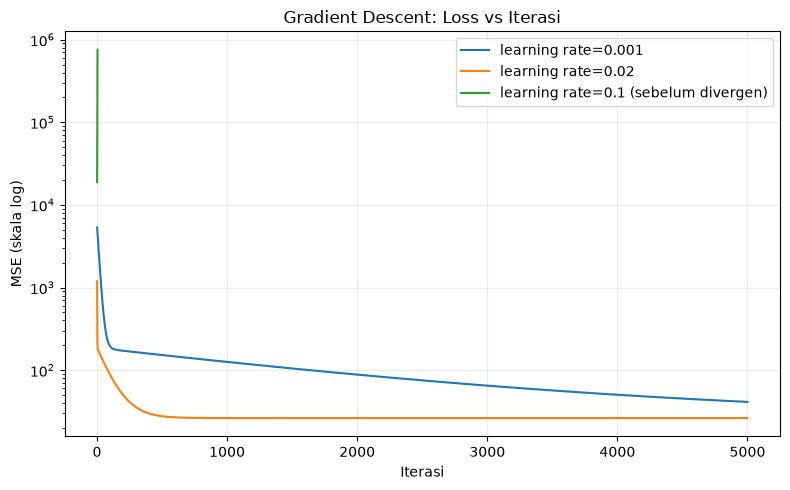

In [22]:
# A5: eksperimen tiga learning rate sesuai soal
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
ringkasan_gd = []
for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model_gd.fit(X_train, y_train)
    gd_models[lr] = model_gd
    loss_arr = np.asarray(model_gd.loss_history_)
    finite_loss = loss_arr[np.isfinite(loss_arr)]
    divergen = (not np.all(np.isfinite(loss_arr))) or (len(finite_loss) and finite_loss[-1] > finite_loss[0])
    baseline_loss = mean_squared_error(y_train, regressor.predict(X_train))
    if divergen:
        status = "Divergen/tidak stabil"
    elif finite_loss[-1] <= baseline_loss * 1.05:
        status = "Konvergen"
    else:
        status = "Lambat (belum konvergen)"
    ringkasan_gd.append({
        "Learning rate": lr,
        "Intercept akhir": model_gd.intercept_,
        "Koefisien akhir": model_gd.coefficients_[0],
        "Loss awal": loss_arr[0],
        "Loss akhir": loss_arr[-1],
        "Status": status
    })
display(pd.DataFrame(ringkasan_gd).round(5))

plt.figure(figsize=(8, 5))
for lr, model_gd in gd_models.items():
    losses = np.asarray(model_gd.loss_history_)
    # Nilai sangat besar dari learning rate divergen tidak diplot agar skala log tetap terbaca.
    valid = np.isfinite(losses) & (losses > 0) & (losses < 1e6)
    if valid.any():
        label = f"learning rate={lr}" if np.all(np.isfinite(losses)) else f"learning rate={lr} (sebelum divergen)"
        plt.plot(np.arange(1, len(losses) + 1)[valid], losses[valid], label=label)
plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.title("Gradient Descent: Loss vs Iterasi")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Jawaban A5 (analisis):**

Learning rate 0,001 menurunkan MSE hingga sekitar 41,2635, tetapi masih di atas MSE training model Normal Equation sebesar 26,2801 setelah 5.000 iterasi; laju ini terlalu lambat untuk mencapai parameter terbaik dalam batas iterasi tersebut. Learning rate 0,02 mencapai MSE sekitar 26,2801 dan parameternya mendekati Normal Equation, sehingga paling sesuai pada eksperimen ini. Learning rate 0,1 menghasilkan parameter dan loss tidak hingga (NaN), menandakan divergensi. Hal ini terjadi karena langkah pembaruan terlalu besar terhadap skala fitur dan target yang digunakan.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

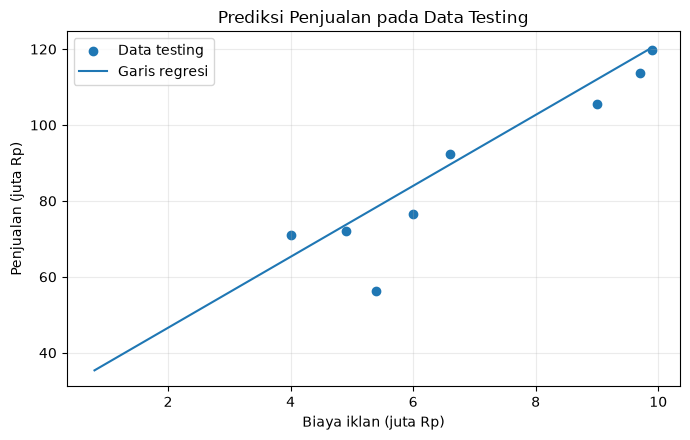

,Biaya iklan (juta Rp),Prediksi penjualan (juta Rp)
0,4.5,69.952
1,7.0,93.321
2,12.0,140.058


Rentang biaya iklan dataset: 0.8–9.9 juta Rp


In [23]:
# A6: grafik data testing dan garis regresi
x_line = np.linspace(float(X.min()), float(X.max()), 200).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test[:, 0], y_test, label="Data testing")
plt.plot(x_line[:, 0], regressor.predict(x_line), label="Garis regresi")
plt.title("Prediksi Penjualan pada Data Testing")
plt.xlabel("Biaya iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = regressor.predict(biaya_baru)
tabel_prediksi_penjualan = pd.DataFrame({
    "Biaya iklan (juta Rp)": biaya_baru[:, 0],
    "Prediksi penjualan (juta Rp)": prediksi_penjualan
})
display(tabel_prediksi_penjualan.round(3))
print(f"Rentang biaya iklan dataset: {X.min():.1f}–{X.max():.1f} juta Rp")

**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan Rp4,5 juta dan Rp7 juta berada dalam rentang data yang diamati (Rp0,8–Rp9,9 juta), sehingga lebih layak digunakan sebagai perkiraan dalam cakupan dataset. Prediksi untuk Rp12 juta merupakan ekstrapolasi di luar rentang tersebut. Karena pola hubungan linear belum tentu terus berlaku pada biaya iklan yang lebih tinggi, hasil Rp12 juta perlu dianggap lebih tidak pasti dan sebaiknya diuji dengan data tambahan.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah data: 60
Jumlah Bukan Spam (0): 35
Jumlah Spam (1): 25
Shape X: (60, 2) | Shape y: (60,)


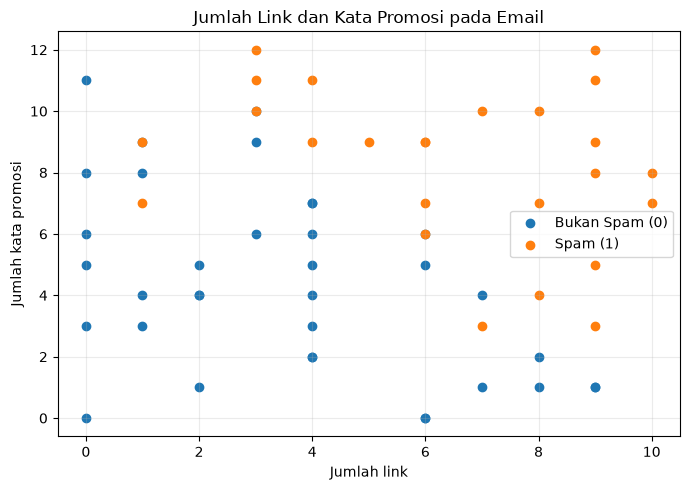

In [24]:
# B1: membaca dataset email, menghitung label, dan visualisasi
email_data = pd.read_csv("Email_Data.csv")
display(email_data.head())
print("Jumlah data:", len(email_data))
print("Jumlah Bukan Spam (0):", int((email_data["Spam"] == 0).sum()))
print("Jumlah Spam (1):", int((email_data["Spam"] == 1).sum()))
X_email = email_data[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email_data["Spam"].to_numpy(dtype=int)
print("Shape X:", X_email.shape, "| Shape y:", y_email.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], label="Bukan Spam (0)")
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], label="Spam (1)")
plt.title("Jumlah Link dan Kata Promosi pada Email")
plt.xlabel("Jumlah link")
plt.ylabel("Jumlah kata promosi")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)
Intercept (b): -12.491747
Koefisien (m1, m2): [1.098748 1.032337]
P(Spam) = sigmoid(b + m1 × JumlahLink + m2 × KataPromo)
P(Spam) = sigmoid(-12.491747 + (1.098748 × JumlahLink) + (1.032337 × KataPromo))


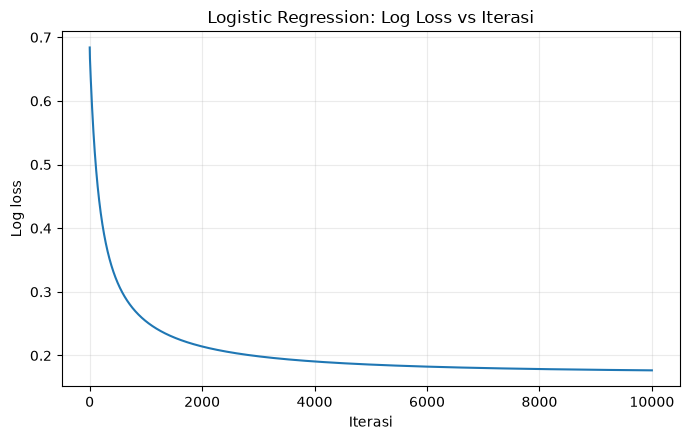

Log loss awal: 0.683973
Log loss akhir: 0.176626


In [25]:
# B2: split data dan training Logistic Regression dengan Gradient Descent
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)
print("X_train:", X_train_email.shape, "| X_test:", X_test_email.shape)
print("y_train:", y_train_email.shape, "| y_test:", y_test_email.shape)

classifier = LogisticRegression(learning_rate=0.1, n_iterations=10000)
classifier.fit(X_train_email, y_train_email)
print(f"Intercept (b): {classifier.intercept_:.6f}")
print("Koefisien (m1, m2):", np.round(classifier.coefficients_, 6))
print("P(Spam) = sigmoid(b + m1 × JumlahLink + m2 × KataPromo)")
print(f"P(Spam) = sigmoid({classifier.intercept_:.6f} + ({classifier.coefficients_[0]:.6f} × JumlahLink) + ({classifier.coefficients_[1]:.6f} × KataPromo))")

plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, len(classifier.loss_history_) + 1), classifier.loss_history_)
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.title("Logistic Regression: Log Loss vs Iterasi")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Log loss awal: {classifier.loss_history_[0]:.6f}")
print(f"Log loss akhir: {classifier.loss_history_[-1]:.6f}")

**Jawaban B2 (analisis):**

Model menghasilkan persamaan P(Spam) = sigmoid(-12,491747 + 1,098748 × JumlahLink + 1,032337 × KataPromo). Kedua koefisien positif menunjukkan bahwa, pada model ini, bertambahnya jumlah link atau kata promosi menaikkan skor probabilitas spam jika fitur lain tetap. Log loss turun dari 0,6840 pada awal pelatihan menjadi 0,1766 setelah 10.000 iterasi, sehingga model semakin menyesuaikan probabilitas dengan label training. Penurunan loss tersebut menunjukkan proses belajar berjalan, meskipun evaluasi testing tetap diperlukan untuk mengukur generalisasi.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [26]:
# B3: evaluasi pada data testing
y_pred_email = classifier.predict(X_test_email, threshold=0.5)
cm_email = confusion_matrix(y_test_email, y_pred_email)
hasil_logistik = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test_email, y_pred_email),
    "Precision": precision_score(y_test_email, y_pred_email),
    "Recall": recall_score(y_test_email, y_pred_email),
    "F1-score": f1_score(y_test_email, y_pred_email)
}])
display(hasil_logistik.round(4))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm_email)
print(f"TN={cm_email[0,0]}, FP={cm_email[0,1]}, FN={cm_email[1,0]}, TP={cm_email[1,1]}")

,Accuracy,Precision,Recall,F1-score
0,0.8,0.8,0.6667,0.7273


Confusion matrix [[TN, FP], [FN, TP]]:
[[8 1]
 [2 4]]
TN=8, FP=1, FN=2, TP=4


**Jawaban B3 (analisis):**

Pada data testing, akurasi model adalah 0,80 (80%), precision 0,80, recall 0,6667, dan F1-score 0,7273. Confusion matrix menunjukkan TN=8, FP=1, FN=2, dan TP=4. False positive (FP) berarti email bukan spam salah ditandai sebagai spam, sedangkan false negative (FN) berarti email spam lolos ke kotak masuk. FP dapat membuat email penting terlewat, sedangkan FN membuat pesan spam tetap masuk; pada konteks email kerja, FP bisa sangat merugikan jika pesan penting tertahan, jadi threshold perlu dipilih sesuai prioritas pengguna.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-12.491747 + (1.098748 × JumlahLink)) / (1.032337)


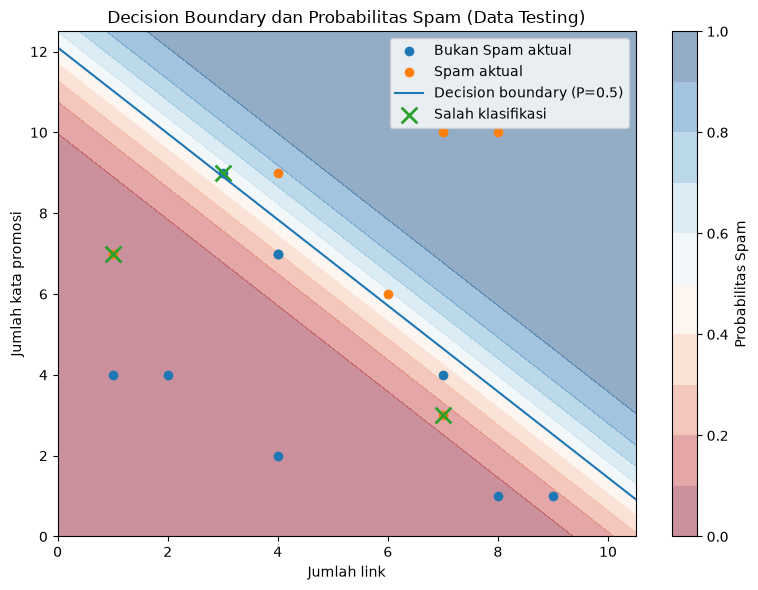

,JumlahLink,KataPromo,Aktual,Prediksi,Probabilitas Spam
0,1,7,1,0,0.0153
1,7,3,1,0,0.1540
2,3,9,0,1,0.5239


In [31]:
# B4: background probabilitas, decision boundary, dan salah klasifikasi
b = classifier.intercept_
m1, m2 = classifier.coefficients_
print(f"Decision boundary: KataPromo = -({b:.6f} + ({m1:.6f} × JumlahLink)) / ({m2:.6f})")
x1_grid, x2_grid = np.meshgrid(
    np.linspace(0, max(10.5, X_email[:, 0].max() + 0.5), 220),
    np.linspace(0, max(12.5, X_email[:, 1].max() + 0.5), 220)
)
grid_points = np.c_[x1_grid.ravel(), x2_grid.ravel()]
prob_grid = classifier.predict_proba(grid_points).reshape(x1_grid.shape)
plt.figure(figsize=(8, 6))
plt.contourf(x1_grid, x2_grid, prob_grid, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=0.45)
plt.colorbar(label="Probabilitas Spam")
plt.scatter(X_test_email[y_test_email == 0, 0], X_test_email[y_test_email == 0, 1], label="Bukan Spam aktual")
plt.scatter(X_test_email[y_test_email == 1, 0], X_test_email[y_test_email == 1, 1], label="Spam aktual")
x1_line = np.linspace(x1_grid.min(), x1_grid.max(), 200)
if abs(m2) > 1e-12:
    x2_line = -(b + m1 * x1_line) / m2
    plt.plot(x1_line, x2_line, label="Decision boundary (P=0.5)")
misclassified = y_pred_email != y_test_email
if np.any(misclassified):
    plt.scatter(X_test_email[misclassified, 0], X_test_email[misclassified, 1],
                marker="x", s=130, linewidths=2, label="Salah klasifikasi")
plt.xlim(x1_grid.min(), x1_grid.max())
plt.ylim(x2_grid.min(), x2_grid.max())
plt.xlabel("Jumlah link")
plt.ylabel("Jumlah kata promosi")
plt.title("Decision Boundary dan Probabilitas Spam (Data Testing)")
plt.legend()
plt.tight_layout()
plt.show()

if np.any(misclassified):
    detail_salah = pd.DataFrame({
        "JumlahLink": X_test_email[misclassified, 0].astype(int),
        "KataPromo": X_test_email[misclassified, 1].astype(int),
        "Aktual": y_test_email[misclassified],
        "Prediksi": y_pred_email[misclassified],
        "Probabilitas Spam": classifier.predict_proba(X_test_email[misclassified]).round(4)
    })
    display(detail_salah)
else:
    print("Tidak ada data testing yang salah diklasifikasikan pada threshold 0.5.")

**Jawaban B4 (analisis):**

Decision boundary model adalah KataPromo = -(-12,491747 + 1,098748 × JumlahLink) / 1,032337, yaitu garis saat probabilitas spam sama dengan 0,5. Pada data testing terdapat tiga kesalahan klasifikasi: dua email spam diprediksi bukan spam dan satu email bukan spam diprediksi sebagai spam. Tanda silang pada grafik menunjukkan ketiga titik tersebut. Kesalahan ini memperlihatkan bahwa dua fitur saja belum dapat memisahkan semua email dengan sempurna.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [28]:
# B5: membandingkan threshold 0.3, 0.5, dan 0.7
prob_test_email = classifier.predict_proba(X_test_email)
ringkasan_threshold = []
prediksi_threshold = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob_test_email >= threshold).astype(int)
    prediksi_threshold[threshold] = pred
    cm = confusion_matrix(y_test_email, pred)
    ringkasan_threshold.append({
        "Threshold": threshold,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
        "Precision": precision_score(y_test_email, pred),
        "Recall": recall_score(y_test_email, pred),
        "Accuracy": accuracy_score(y_test_email, pred)
    })
tabel_threshold = pd.DataFrame(ringkasan_threshold)
display(tabel_threshold.round(4))

,Threshold,TN,FP,FN,TP,Precision,Recall,Accuracy
0,0.3,7,2,2,4,0.6667,0.6667,0.7333
1,0.5,8,1,2,4,0.8000,0.6667,0.8000
2,0.7,9,0,3,3,1.0000,0.5000,0.8000


**Jawaban B5 (analisis):**

Threshold 0,3 menghasilkan precision 0,6667 dan recall 0,6667, dengan FP=2 dan FN=2. Threshold 0,5 menghasilkan precision 0,80 dan recall 0,6667, dengan FP=1 dan FN=2. Threshold 0,7 menghasilkan precision 1,00 dan recall 0,50, tanpa FP tetapi FN meningkat menjadi 3. Untuk tugas ini saya memilih threshold 0,5 karena memberi keseimbangan yang cukup baik: hanya satu email bukan spam yang keliru ditandai spam, sementara recall tetap sama seperti threshold 0,3 dan lebih tinggi daripada threshold 0,7.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [29]:
# B6: prediksi probabilitas spam untuk empat email baru
# Threshold pilihan: 0.5 sebagai titik tengah; hasil threshold lain tersedia di B5.
threshold_pilihan = 0.5
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
email_baru["Probabilitas Spam"] = classifier.predict_proba(X_baru)
email_baru["Prediksi (threshold 0.5)"] = (email_baru["Probabilitas Spam"] >= threshold_pilihan).astype(int)
email_baru["Keterangan"] = email_baru["Prediksi (threshold 0.5)"].map({0: "Bukan Spam", 1: "Spam"})
display(email_baru.round(4))

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi (threshold 0.5),Keterangan
0,E1,1,2,0.0001,0,Bukan Spam
1,E2,5,6,0.3092,0,Bukan Spam
2,E3,9,10,0.9996,1,Spam
3,E4,2,11,0.7430,1,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena hasil akhirnya berupa kelas, misalnya spam atau bukan spam, bukan nilai kontinu seperti pada regresi linear. Model menghitung kombinasi berbobot dari fitur lalu memasukkannya ke fungsi sigmoid. Sigmoid mengubah nilai tersebut menjadi probabilitas antara 0 dan 1. Probabilitas itu dibandingkan dengan threshold untuk menentukan kelas prediksi.

**Jawaban C2:** Normal Equation menghitung parameter regresi secara langsung melalui operasi matriks, sehingga tidak perlu menentukan learning rate atau jumlah iterasi. Gradient Descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss. Gradient Descent lebih sesuai untuk data berukuran besar atau ketika perhitungan langsung matriks menjadi mahal. Namun, hasilnya dipengaruhi learning rate, jumlah iterasi, dan skala fitur.

**Jawaban C3:** Data training digunakan untuk mempelajari parameter, sehingga evaluasi pada data itu saja dapat memberi gambaran yang terlalu optimistis. Data testing digunakan untuk menilai kemampuan model pada data yang tidak ikut dilatih. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan pola atau noise data training sehingga performanya menurun pada data baru. Karena itu, hasil training dan testing perlu dibandingkan.

**Jawaban C4:** Linear Regression menghasilkan nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih antara nilai aktual dan prediksi. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai seberapa baik probabilitas tersebut sesuai dengan label sebenarnya. Log loss memberi penalti besar ketika model memberikan probabilitas yang sangat yakin tetapi salah. Kedua loss dipilih karena sesuai dengan jenis output dan tujuan masing-masing model.

**Jawaban C5:** Hasil dapat berbeda jika pembagian training dan testing atau nilai random state berbeda, karena model dilatih menggunakan bagian data yang berbeda. Hasil juga dapat dipengaruhi learning rate, jumlah iterasi, inisialisasi parameter, dan regularisasi. Bahkan dengan dataset sama, implementasi atau pengaturan algoritma yang tidak sama dapat menghasilkan koefisien dan metrik berbeda. Karena itu, eksperimen perlu mencatat konfigurasi yang digunakan agar perbandingan adil.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [30]:
# BONUS: perbandingan implementasi NumPy dengan scikit-learn
# Scikit-learn hanya digunakan pada bagian bonus sesuai instruksi.
from sklearn.linear_model import LinearRegression as SklearnLinearRegression
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.metrics import mean_absolute_error as sk_mae, mean_squared_error as sk_mse, r2_score as sk_r2
from sklearn.metrics import accuracy_score as sk_accuracy, confusion_matrix as sk_confusion_matrix
from sklearn.metrics import precision_score as sk_precision, recall_score as sk_recall, f1_score as sk_f1

sk_reg = SklearnLinearRegression().fit(X_train, y_train)
sk_y_pred = sk_reg.predict(X_test)
perbandingan_regresi = pd.DataFrame([
    {"Model": "Implementasi NumPy", "Intercept": regressor.intercept_,
     "Koefisien": regressor.coefficients_[0],
     "MAE testing": mean_absolute_error(y_test, regressor.predict(X_test)),
     "MSE testing": mean_squared_error(y_test, regressor.predict(X_test)),
     "R² testing": r2_score(y_test, regressor.predict(X_test))},
    {"Model": "scikit-learn", "Intercept": sk_reg.intercept_,
     "Koefisien": sk_reg.coef_[0],
     "MAE testing": sk_mae(y_test, sk_y_pred),
     "MSE testing": sk_mse(y_test, sk_y_pred),
     "R² testing": sk_r2(y_test, sk_y_pred)}
])
print("Perbandingan Linear Regression")
display(perbandingan_regresi.round(6))

# Logistic Regression scikit-learn memakai regularisasi L2 secara default.
# C besar berarti regularisasi lebih lemah; gunakan C=1e6 untuk mendekati tanpa regularisasi.
sk_clf = SklearnLogisticRegression(C=1e6, max_iter=10000, solver="lbfgs")
sk_clf.fit(X_train_email, y_train_email)
sk_y_pred = sk_clf.predict(X_test_email)
sk_proba = sk_clf.predict_proba(X_test_email)[:, 1]
pred_numpy = classifier.predict(X_test_email, threshold=0.5)
perbandingan_logistik = pd.DataFrame([
    {"Model": "Implementasi NumPy", "Intercept": classifier.intercept_,
     "Koefisien link": classifier.coefficients_[0], "Koefisien promo": classifier.coefficients_[1],
     "Accuracy": accuracy_score(y_test_email, pred_numpy),
     "Precision": precision_score(y_test_email, pred_numpy),
     "Recall": recall_score(y_test_email, pred_numpy), "F1-score": f1_score(y_test_email, pred_numpy)},
    {"Model": "scikit-learn (C=1e6)", "Intercept": sk_clf.intercept_[0],
     "Koefisien link": sk_clf.coef_[0, 0], "Koefisien promo": sk_clf.coef_[0, 1],
     "Accuracy": sk_accuracy(y_test_email, sk_y_pred),
     "Precision": sk_precision(y_test_email, sk_y_pred, zero_division=0),
     "Recall": sk_recall(y_test_email, sk_y_pred, zero_division=0),
     "F1-score": sk_f1(y_test_email, sk_y_pred, zero_division=0)}
])
print("Perbandingan Logistic Regression")
display(perbandingan_logistik.round(6))
print("Confusion matrix scikit-learn [[TN, FP], [FN, TP]]:")
print(sk_confusion_matrix(y_test_email, sk_y_pred))

Perbandingan Linear Regression


,Model,Intercept,Koefisien,MAE testing,MSE testing,R² testing
0,Implementasi NumPy,27.888442,9.347443,6.446382,80.749225,0.824097
1,scikit-learn,27.888442,9.347443,6.446382,80.749225,0.824097


Perbandingan Logistic Regression


,Model,Intercept,Koefisien link,Koefisien promo,Accuracy,Precision,Recall,F1-score
0,Implementasi NumPy,-12.491747,1.098748,1.032337,0.8,0.8,0.666667,0.727273
1,scikit-learn (C=1e6),-15.184610,1.334604,1.247983,0.8,0.8,0.666667,0.727273


Confusion matrix scikit-learn [[TN, FP], [FN, TP]]:
[[8 1]
 [2 4]]


**Jawaban Bonus (analisis):**

Perbandingan menggunakan pembagian data yang sama. Linear Regression implementasi NumPy dan scikit-learn menghasilkan intercept, koefisien, serta metrik testing yang sama hingga presisi yang ditampilkan (MAE 6,4464; MSE 80,7492; R² 0,8241). Pada Logistic Regression, kedua model menghasilkan metrik klasifikasi testing yang sama pada threshold 0,5 (accuracy 0,80; precision 0,80; recall 0,6667; F1-score 0,7273), tetapi koefisien berbeda: implementasi NumPy memiliki intercept sekitar -12,4917, sedangkan scikit-learn sekitar -15,1846. Salah satu penyebabnya adalah pengaturan optimasi dan regularisasi: scikit-learn menggunakan regularisasi L2 secara default, dan walaupun C=1e6 membuatnya sangat lemah, konfigurasi solver serta kriteria berhenti masih berbeda.